# 05 — Model evaluation

Inspect the **saved** winner on 2020 test hours. We do not retrain here.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import sys
import matplotlib.pyplot as plt
import pandas as pd

def project_root() -> Path:
    here = Path.cwd()
    for candidate in (here, here.parent):
        if (candidate / "models" / "forecast_model.joblib").exists():
            return candidate
    raise FileNotFoundError("Run: python ml_pipeline/train.py")

ROOT = project_root()
sys.path.insert(0, str(ROOT / "backend"))
from app.ml.predictor import load_forecast_artifact, predict_forecast
from app.ml.split import time_split
from app.ml.features import TARGET_COLUMN

metadata = json.loads((ROOT / "models" / "model_metadata.json").read_text(encoding="utf-8"))
features = pd.read_csv(ROOT / "data" / "processed" / "spain_hourly_features.csv")
_, _, test = time_split(features)
artifact = load_forecast_artifact(ROOT / "models" / "forecast_model.joblib")
test = test.copy()
test["predicted_load_mw"] = predict_forecast(artifact, test)
test["residual_mw"] = test["predicted_load_mw"] - test[TARGET_COLUMN]
test["utc"] = pd.to_datetime(test["utc_timestamp"], utc=True)
print("Selected:", metadata["selected_model"])
print(metadata["metrics"][metadata["selected_model"]])

Selected: hist_gradient_boosting
{'train': {'mae': 207.13, 'rmse': 316.9, 'mape': 0.725}, 'valid': {'mae': 227.02, 'rmse': 313.49, 'mape': 0.801}, 'test': {'mae': 311.33, 'rmse': 443.58, 'mape': 1.237}}


## Actual vs predicted (one test week in January 2020, before the main lockdown drop)

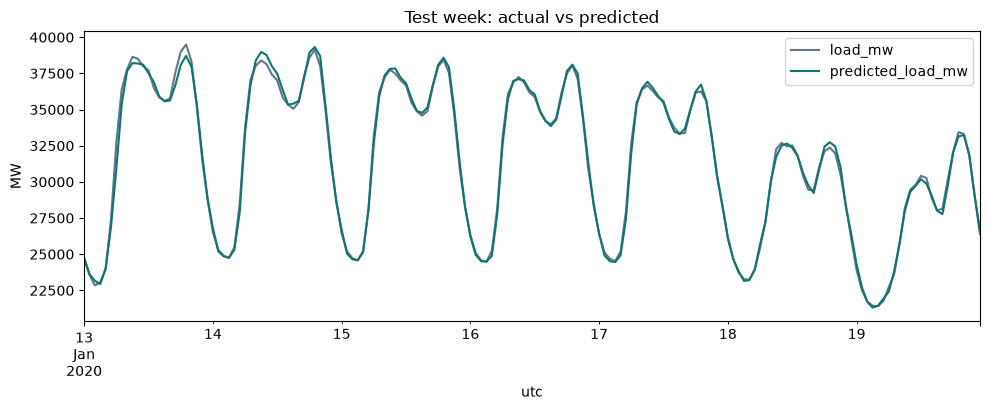

In [2]:
week = test[(test["utc"] >= "2020-01-13") & (test["utc"] < "2020-01-20")]
ax = week.set_index("utc")[[TARGET_COLUMN, "predicted_load_mw"]].plot(
    figsize=(10, 4.2), color=["#64748b", "#0f766e"]
)
ax.set_ylabel("MW")
ax.set_title("Test week: actual vs predicted")
plt.tight_layout()
plt.show()

## Residuals

A residual is predicted − actual. If residuals fan out over time or are huge on weekends only, the model is missing a pattern. Random scatter around zero is what we want.

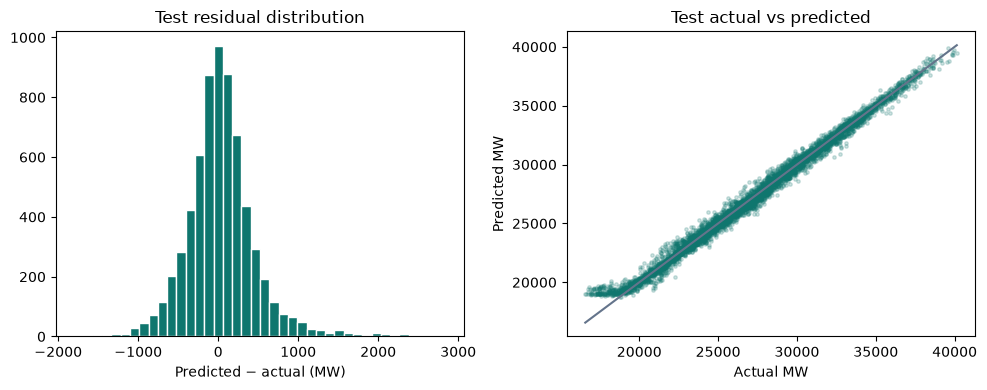

Residual mean MW: 38.47
Residual std MW: 441.94


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(test["residual_mw"], bins=40, color="#0f766e", edgecolor="white")
axes[0].set_title("Test residual distribution")
axes[0].set_xlabel("Predicted − actual (MW)")
axes[1].scatter(test[TARGET_COLUMN], test["predicted_load_mw"], s=6, alpha=0.2, color="#0f766e")
axes[1].plot(
    [test[TARGET_COLUMN].min(), test[TARGET_COLUMN].max()],
    [test[TARGET_COLUMN].min(), test[TARGET_COLUMN].max()],
    color="#64748b",
)
axes[1].set_xlabel("Actual MW")
axes[1].set_ylabel("Predicted MW")
axes[1].set_title("Test actual vs predicted")
plt.tight_layout()
plt.show()
print("Residual mean MW:", round(test["residual_mw"].mean(), 2))
print("Residual std MW:", round(test["residual_mw"].std(), 2))

MAE is easier to explain than RMSE: on 2020 test hours the selected model is off by about **311 MW on average**. Mean Spanish demand is around 28,000 MW, so that is a bit over 1% MAPE.

This is still an estimate, not an operational dispatch tool.